# Tugas 6 - Pengolahan Citra Digital
## Deteksi Keberadaan Tanda Tangan Menggunakan Thresholding dan Morphological Operation

### Nama
Nama: Rahmat Kurniawan

NIM : F1G124048

### Mata Kuliah
Pengolahan Citra Digital

---

## Deskripsi

Mini-project ini bertujuan untuk melakukan segmentasi area tanda tangan
pada dokumen dan menentukan keberadaan tanda tangan menggunakan pengolahan
citra digital.

Tahapan pengolahan citra yang digunakan meliputi:

1. Crop area tanda tangan.
2. Konversi citra menjadi grayscale.
3. Global thresholding.
4. Otsu thresholding.
5. Morphological opening.
6. Morphological closing.
7. Perhitungan jumlah dan persentase piksel foreground.
8. Klasifikasi menjadi `SIGNATURE PRESENT` atau `SIGNATURE ABSENT`.
9. Evaluasi sistem menggunakan beberapa citra yang memiliki tanda tangan
   dan citra yang tidak memiliki tanda tangan.

## 1. Dataset

Dataset utama terdiri dari 9 citra dokumen yang memiliki tanda tangan
dengan berbagai kondisi kualitas citra, seperti:

- High Quality
- Blurred
- Low Contrast
- High Noise
- JPEG Compression Artifacts
- Color Shift
- Combined Degradation
- Faded / Underexposed
- Low Resolution / Upsampled

Untuk pengujian klasifikasi keberadaan tanda tangan, digunakan tambahan
9 citra `SIGNATURE ABSENT` yang dibuat dari citra yang sama dengan
menghilangkan tanda tangan.

Dengan demikian, dataset pengujian terdiri dari:

- 9 citra `SIGNATURE PRESENT`
- 9 citra `SIGNATURE ABSENT`

Total: **18 citra**.

In [60]:
import pandas as pd
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("Library berhasil diimpor!")


Library berhasil diimpor!


In [61]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [62]:
folder = "/content/drive/MyDrive/Tugas 6 citra digital"

print(os.listdir(folder))

['Copy of 01_HighQuality_Enhanced.jpg', 'Copy of 03_Blurred.jpg', 'Copy of 02_LowContrast.jpg', 'Copy of 04_HighNoise.jpg', 'Copy of 08_JPEGCompression_Artifacts.jpg', 'Copy of 07_ColorShift_WarmTint.jpg', 'Copy of 09_CombinedDegradation.jpg', 'Copy of 06_Faded_Underexposed.jpg', 'Copy of 05_LowResolution_Upsampled.jpg']


Jumlah gambar: 9


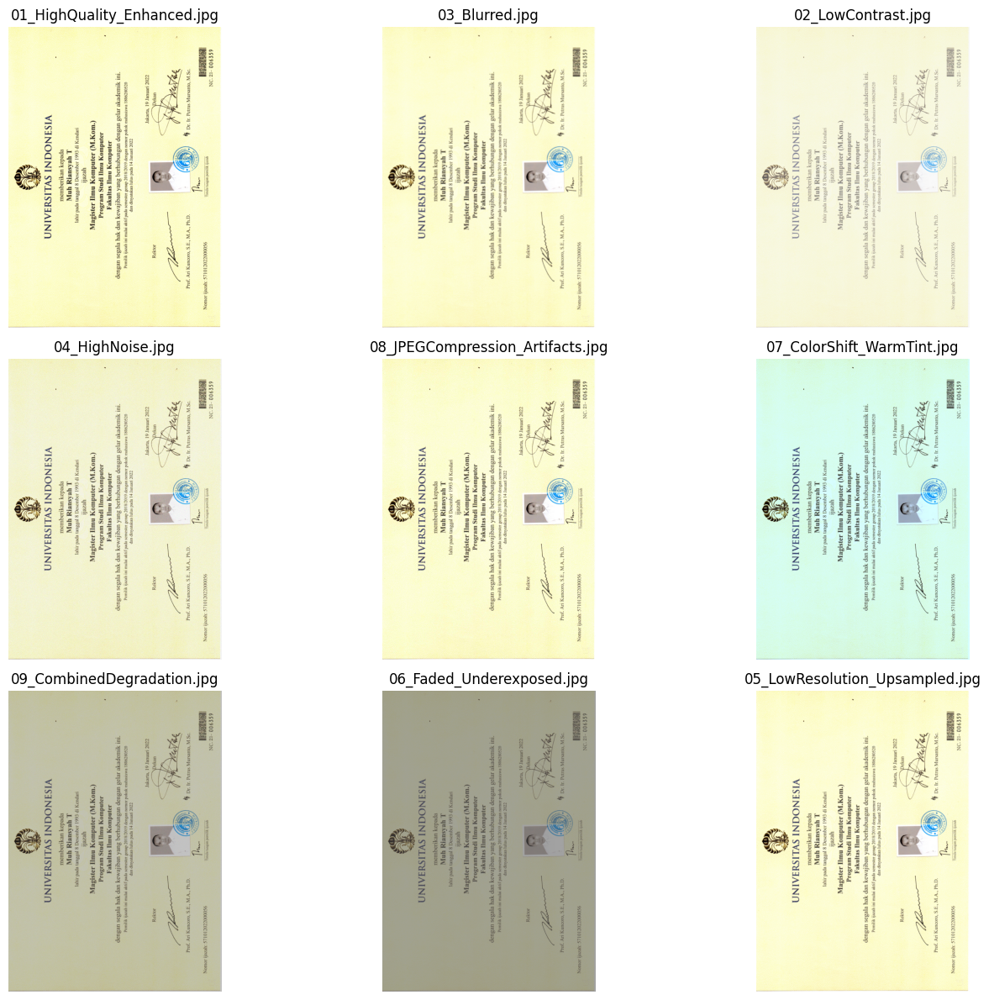

In [63]:
# Ambil semua file gambar
files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

print("Jumlah gambar:", len(files))

# Tampilkan semua gambar
plt.figure(figsize=(15, 12))

for i, nama_file in enumerate(files):
    path = os.path.join(folder, nama_file)

    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(nama_file.replace("Copy of ", ""))
    plt.axis("off")

plt.tight_layout()
plt.show()

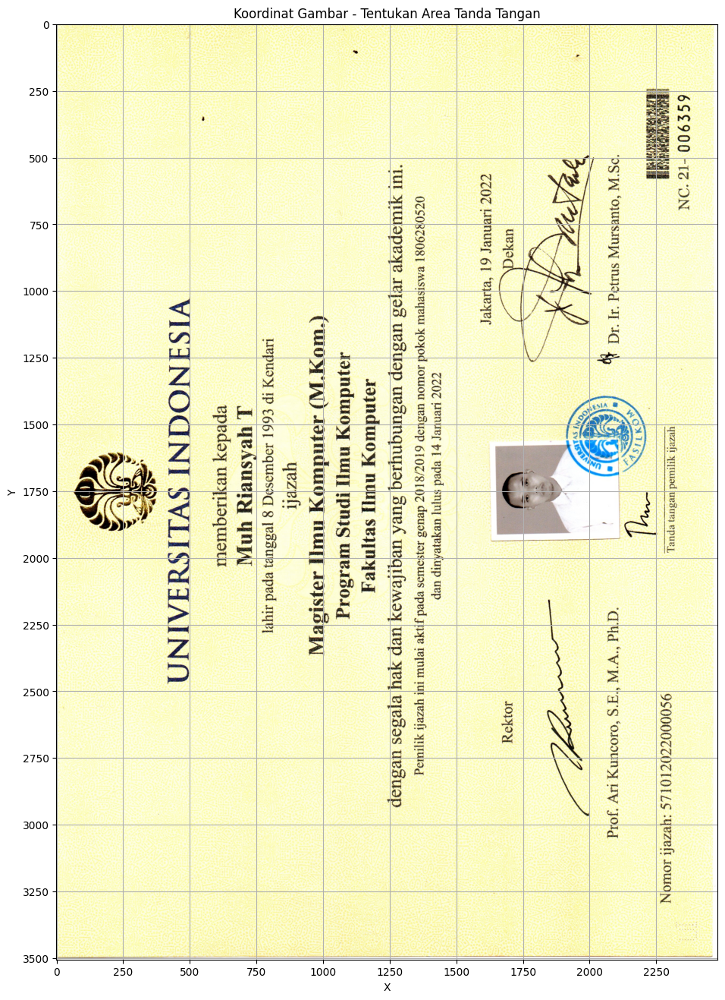

In [64]:
# Baca gambar
nama_file = files[0]
path = os.path.join(folder, nama_file)

img = cv2.imread(path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Tampilkan dengan ukuran lebih besar
plt.figure(figsize=(12, 16))
plt.imshow(img_rgb)

# Tampilkan koordinat
plt.xticks(range(0, 2481, 250))
plt.yticks(range(0, 3507, 250))
plt.grid()

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Koordinat Gambar - Tentukan Area Tanda Tangan")

plt.show()

## 2. Crop Area Tanda Tangan

Tahap pertama adalah mengambil area dokumen yang diperkirakan
mengandung tanda tangan. Cropping dilakukan agar proses segmentasi
hanya berfokus pada area tanda tangan dan tidak terpengaruh oleh
bagian dokumen lainnya.

Koordinat crop ditentukan berdasarkan posisi area tanda tangan pada
citra.

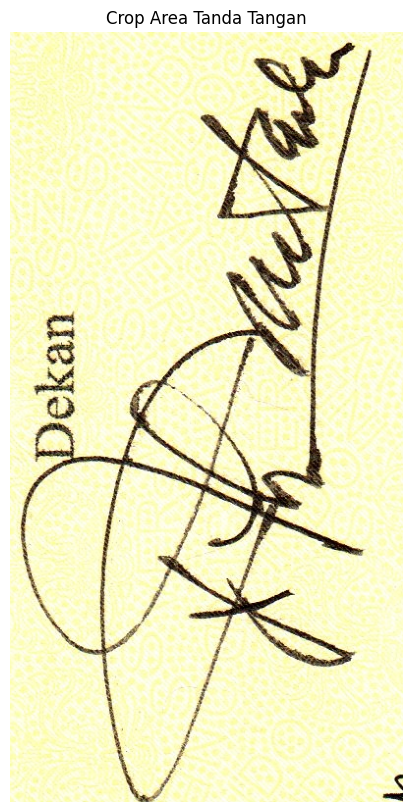

In [65]:
 # Koordinat crop sementara
x1 = 1650
y1 = 480
x2 = 2050
y2 = 1265

    # Crop
crop = img[y1:y2, x1:x2]

    # Konversi BGR → RGB
crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

    # Tampilkan hasil crop
plt.figure(figsize=(8, 10))
plt.imshow(crop_rgb)
plt.axis("off")
plt.title("Crop Area Tanda Tangan")
plt.show()

### Hasil Crop

Hasil cropping menunjukkan area yang digunakan sebagai input untuk
tahap pengolahan citra berikutnya.

## 3. Konversi Grayscale

Citra hasil crop dikonversi dari citra berwarna menjadi grayscale.
Konversi ini diperlukan karena proses thresholding bekerja berdasarkan
nilai intensitas piksel.

Dengan grayscale, setiap piksel direpresentasikan menggunakan satu
nilai intensitas dari gelap hingga terang sehingga proses segmentasi
menjadi lebih sederhana.

In [66]:
# Koordinat area tanda tangan
x1 = 1650
y1 = 480
x2 = 2050
y2 = 1265

# Menyimpan hasil grayscale
grayscale_images = {}

# Proses semua gambar
for nama_file in files:

    # Path gambar
    path = os.path.join(folder, nama_file)

    # Baca gambar
    img = cv2.imread(path)

    # Crop area tanda tangan
    crop = img[y1:y2, x1:x2]

    # Konversi ke grayscale
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)

    # Simpan hasil grayscale
    grayscale_images[nama_file] = gray

print("Berhasil mengubah", len(grayscale_images), "gambar menjadi grayscale.")

Berhasil mengubah 9 gambar menjadi grayscale.


### Hasil Grayscale

Citra grayscale kemudian digunakan sebagai input untuk proses
thresholding.

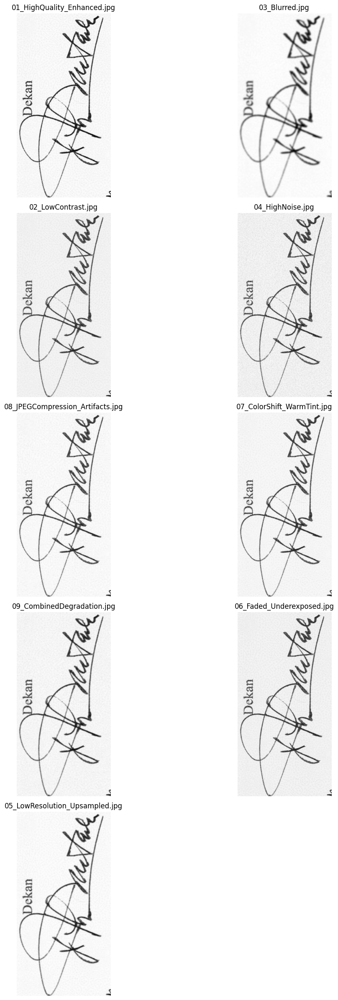

In [67]:
plt.figure(figsize=(12, 24))

for i, nama_file in enumerate(files):

    gray = grayscale_images[nama_file]

    plt.subplot(5, 2, i + 1)
    plt.imshow(gray, cmap="gray")
    plt.title(nama_file.replace("Copy of ", ""))
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Global Thresholding

Global thresholding menggunakan satu nilai threshold yang sama untuk
seluruh citra.

Pada implementasi ini digunakan nilai threshold **127**.

Piksel yang memenuhi kondisi threshold akan dikategorikan sebagai
foreground, sedangkan piksel lainnya dikategorikan sebagai background.

Metode ini sederhana, tetapi hasilnya dapat dipengaruhi oleh kondisi
pencahayaan, kontras, dan kualitas citra.

In [68]:
#Menerapkan global treshold
# Nilai threshold global
threshold_value = 127

# Menyimpan hasil Global Threshold
global_threshold_images = {}

# Proses semua gambar grayscale
for nama_file, gray in grayscale_images.items():

    # Global Threshold
    _, global_thresh = cv2.threshold(
        gray,
        threshold_value,
        255,
        cv2.THRESH_BINARY_INV
    )

    # Simpan hasil
    global_threshold_images[nama_file] = global_thresh

print("Global Threshold berhasil diterapkan pada",
      len(global_threshold_images), "gambar.")

Global Threshold berhasil diterapkan pada 9 gambar.


### Hasil Global Thresholding

Hasil global thresholding kemudian digunakan untuk melihat bagaimana
satu nilai threshold tetap bekerja pada citra dengan kondisi kualitas
yang berbeda.

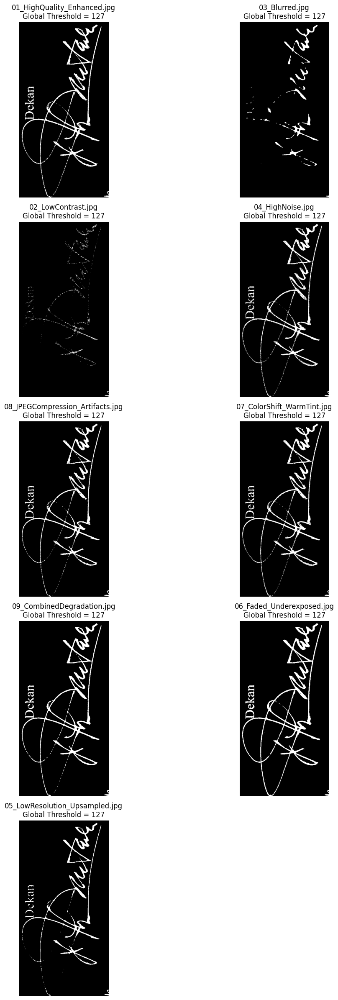

In [69]:
#HAsil dari Global treshold
plt.figure(figsize=(12, 24))

for i, nama_file in enumerate(files):

    global_thresh = global_threshold_images[nama_file]

    plt.subplot(5, 2, i + 1)
    plt.imshow(global_thresh, cmap="gray")
    plt.title(
        nama_file.replace("Copy of ", "") +
        f"\nGlobal Threshold = {threshold_value}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [70]:
#PErhitungan Nilai
global_results = []

for nama_file, global_thresh in global_threshold_images.items():

    foreground = np.sum(global_thresh == 255)

    total_pixels = global_thresh.shape[0] * global_thresh.shape[1]

    percentage = (foreground / total_pixels) * 100

    global_results.append({
        "file": nama_file,
        "foreground": foreground,
        "percentage": percentage
    })

for data in global_results:
    print(
        data["file"],
        "| Foreground:", data["foreground"],
        "| Percentage:", f"{data['percentage']:.2f}%"
    )

Copy of 01_HighQuality_Enhanced.jpg | Foreground: 23721 | Percentage: 7.55%
Copy of 03_Blurred.jpg | Foreground: 9428 | Percentage: 3.00%
Copy of 02_LowContrast.jpg | Foreground: 3362 | Percentage: 1.07%
Copy of 04_HighNoise.jpg | Foreground: 21162 | Percentage: 6.74%
Copy of 08_JPEGCompression_Artifacts.jpg | Foreground: 20989 | Percentage: 6.68%
Copy of 07_ColorShift_WarmTint.jpg | Foreground: 22190 | Percentage: 7.07%
Copy of 09_CombinedDegradation.jpg | Foreground: 23833 | Percentage: 7.59%
Copy of 06_Faded_Underexposed.jpg | Foreground: 27623 | Percentage: 8.80%
Copy of 05_LowResolution_Upsampled.jpg | Foreground: 17855 | Percentage: 5.69%


## 5. Otsu Thresholding

Selain global thresholding, digunakan metode Otsu thresholding.

Otsu menentukan nilai threshold secara otomatis berdasarkan distribusi
intensitas piksel pada citra. Dengan demikian, nilai threshold dapat
berbeda untuk setiap citra sesuai dengan karakteristik intensitasnya.

Metode ini digunakan untuk melihat apakah segmentasi dapat menjadi
lebih adaptif dibandingkan penggunaan satu nilai threshold tetap.

In [71]:
# Menyimpan hasil Otsu Threshold
otsu_threshold_images = {}

# Menyimpan nilai threshold Otsu setiap gambar
otsu_values = {}

# Proses semua gambar grayscale
for nama_file, gray in grayscale_images.items():

    # Otsu Threshold
    otsu_value, otsu_thresh = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Simpan hasil threshold
    otsu_threshold_images[nama_file] = otsu_thresh

    # Simpan nilai threshold Otsu
    otsu_values[nama_file] = otsu_value

print("Otsu Threshold berhasil diterapkan pada",
      len(otsu_threshold_images), "gambar.")

Otsu Threshold berhasil diterapkan pada 9 gambar.


### Hasil Otsu Thresholding

Nilai threshold Otsu berbeda pada masing-masing citra karena setiap
citra memiliki kondisi intensitas dan kualitas yang berbeda.

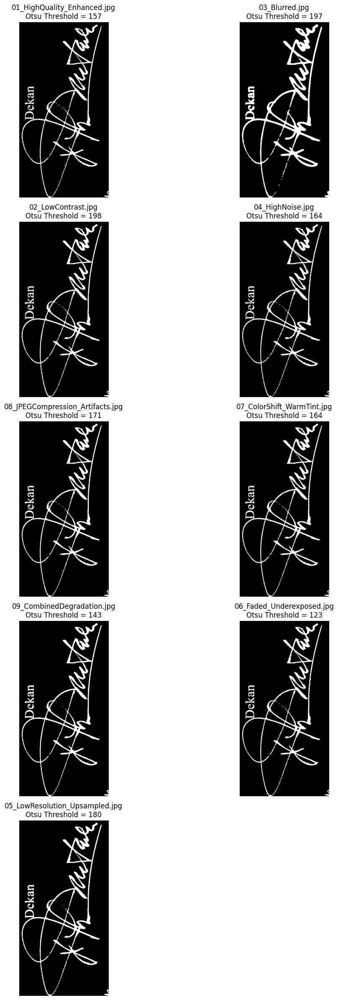

In [72]:
#Menampilkan hasil threshold Otsu

plt.figure(figsize=(12, 24))

for i, nama_file in enumerate(files):

    otsu_thresh = otsu_threshold_images[nama_file]
    otsu_value = otsu_values[nama_file]

    plt.subplot(5, 2, i + 1)
    plt.imshow(otsu_thresh, cmap="gray")

    plt.title(
        nama_file.replace("Copy of ", "") +
        f"\nOtsu Threshold = {otsu_value:.0f}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [73]:
#Menghitung nilai otsu treshold
otsu_results = []

for nama_file, otsu_thresh in otsu_threshold_images.items():

    foreground = np.sum(otsu_thresh == 255)

    total_pixels = otsu_thresh.shape[0] * otsu_thresh.shape[1]

    percentage = (foreground / total_pixels) * 100

    otsu_results.append({
        "file": nama_file,
        "otsu_threshold": otsu_values[nama_file],
        "foreground": foreground,
        "percentage": percentage
    })

for data in otsu_results:

    print(
        data["file"],
        "| Otsu:", data["otsu_threshold"],
        "| Foreground:", data["foreground"],
        "| Percentage:",
        f"{data['percentage']:.2f}%"
    )

Copy of 01_HighQuality_Enhanced.jpg | Otsu: 157.0 | Foreground: 26540 | Percentage: 8.45%
Copy of 03_Blurred.jpg | Otsu: 197.0 | Foreground: 37523 | Percentage: 11.95%
Copy of 02_LowContrast.jpg | Otsu: 198.0 | Foreground: 26797 | Percentage: 8.53%
Copy of 04_HighNoise.jpg | Otsu: 164.0 | Foreground: 26028 | Percentage: 8.29%
Copy of 08_JPEGCompression_Artifacts.jpg | Otsu: 171.0 | Foreground: 26895 | Percentage: 8.57%
Copy of 07_ColorShift_WarmTint.jpg | Otsu: 164.0 | Foreground: 26749 | Percentage: 8.52%
Copy of 09_CombinedDegradation.jpg | Otsu: 143.0 | Foreground: 28427 | Percentage: 9.05%
Copy of 06_Faded_Underexposed.jpg | Otsu: 123.0 | Foreground: 26809 | Percentage: 8.54%
Copy of 05_LowResolution_Upsampled.jpg | Otsu: 180.0 | Foreground: 29329 | Percentage: 9.34%


## 6. Perbandingan Global Threshold dan Otsu Threshold

Hasil kedua metode dibandingkan berdasarkan persentase piksel
foreground yang dihasilkan.

Persentase foreground dihitung dengan rumus:

**Foreground (%) = (Jumlah piksel foreground / Jumlah seluruh piksel) × 100%**

Perbandingan ini digunakan untuk melihat pengaruh metode thresholding
terhadap hasil segmentasi area tanda tangan.

In [74]:
# Tabel perbandingan Global Threshold dan Otsu Threshold

df_global_vs_otsu = df_comparison[
    ["Citra", "Global (%)", "Otsu Threshold", "Otsu (%)"]
].copy()

display(df_global_vs_otsu)

,Citra,Global (%),Otsu Threshold,Otsu (%)
0,01_HighQuality_Enhanced.jpg,7.55,157.0,8.45
1,03_Blurred.jpg,3.00,197.0,11.95
2,02_LowContrast.jpg,1.07,198.0,8.53
3,04_HighNoise.jpg,6.74,164.0,8.29
4,08_JPEGCompression_Artifacts.jpg,6.68,171.0,8.57
5,07_ColorShift_WarmTint.jpg,7.07,164.0,8.52
6,09_CombinedDegradation.jpg,7.59,143.0,9.05
7,06_Faded_Underexposed.jpg,8.80,123.0,8.54
8,05_LowResolution_Upsampled.jpg,5.69,180.0,9.34


## 7. Morphological Opening

Setelah proses Otsu thresholding, diterapkan morphological opening
untuk mengurangi noise atau objek kecil yang tidak diperlukan.

Opening terdiri dari operasi:

**Erosion → Dilation**

Pada eksperimen ini digunakan kernel berukuran **3 × 3**.

Opening diharapkan dapat menghilangkan sebagian noise kecil tanpa
menghilangkan struktur utama tanda tangan.

In [75]:

# Kernel untuk morphological operation
kernel = np.ones((3, 3), np.uint8)

# Menyimpan hasil Opening
opening_images = {}

# Proses semua hasil Otsu
for nama_file, otsu_thresh in otsu_threshold_images.items():

    # Morphological Opening
    opening = cv2.morphologyEx(
        otsu_thresh,
        cv2.MORPH_OPEN,
        kernel
    )

    # Simpan hasil
    opening_images[nama_file] = opening

print(
    "Morphological Opening berhasil diterapkan pada",
    len(opening_images),
    "gambar."
)

Morphological Opening berhasil diterapkan pada 9 gambar.


### Hasil Opening

Hasil opening menunjukkan adanya pengurangan beberapa piksel
foreground kecil yang dianggap sebagai noise.

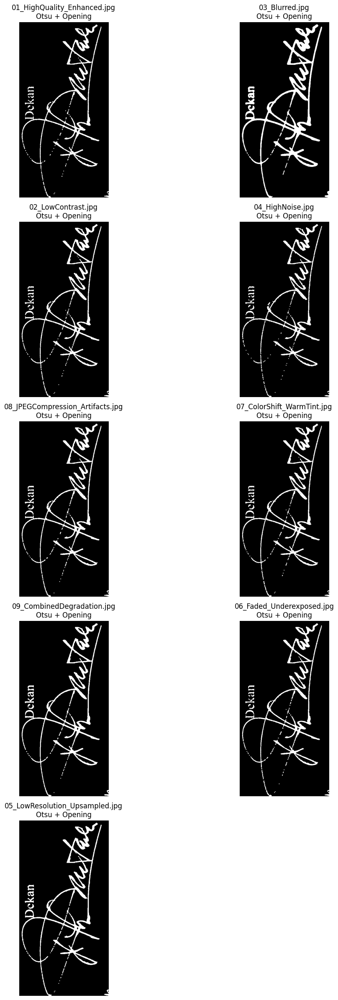

In [76]:
#hasil Opening semua gambar
plt.figure(figsize=(12, 24))

for i, nama_file in enumerate(files):

    opening = opening_images[nama_file]

    plt.subplot(5, 2, i + 1)
    plt.imshow(opening, cmap="gray")
    plt.title(
        nama_file.replace("Copy of ", "") +
        "\nOtsu + Opening"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

##Perhitung karakteristik area hasil segmentasi opening

In [77]:
opening_results = []

for nama_file, opening in opening_images.items():

    foreground = np.sum(opening == 255)

    total_pixels = opening.shape[0] * opening.shape[1]

    percentage = (foreground / total_pixels) * 100

    opening_results.append({
        "file": nama_file,
        "foreground": foreground,
        "percentage": percentage
    })

for data in opening_results:

    print(
        data["file"],
        "| Foreground:", data["foreground"],
        "| Percentage:",
        f"{data['percentage']:.2f}%"
    )

Copy of 01_HighQuality_Enhanced.jpg | Foreground: 24672 | Percentage: 7.86%
Copy of 03_Blurred.jpg | Foreground: 37276 | Percentage: 11.87%
Copy of 02_LowContrast.jpg | Foreground: 25193 | Percentage: 8.02%
Copy of 04_HighNoise.jpg | Foreground: 23634 | Percentage: 7.53%
Copy of 08_JPEGCompression_Artifacts.jpg | Foreground: 25600 | Percentage: 8.15%
Copy of 07_ColorShift_WarmTint.jpg | Foreground: 25140 | Percentage: 8.01%
Copy of 09_CombinedDegradation.jpg | Foreground: 27670 | Percentage: 8.81%
Copy of 06_Faded_Underexposed.jpg | Foreground: 25323 | Percentage: 8.06%
Copy of 05_LowResolution_Upsampled.jpg | Foreground: 28800 | Percentage: 9.17%


## 8. Morphological Closing

Selain opening, diterapkan morphological closing.

Closing terdiri dari operasi:

**Dilation → Erosion**

Closing digunakan untuk menutup celah kecil dan menghubungkan bagian
foreground yang terputus.

Kernel yang digunakan tetap berukuran **3 × 3** agar perbandingan
dengan morphological opening tetap konsisten.

In [78]:

# Kernel untuk morphological operation
kernel = np.ones((3, 3), np.uint8)

# Menyimpan hasil Closing
closing_images = {}

# Proses semua hasil Otsu
for nama_file, otsu_thresh in otsu_threshold_images.items():

    # Morphological Closing
    closing = cv2.morphologyEx(
        otsu_thresh,
        cv2.MORPH_CLOSE,
        kernel
    )

    # Simpan hasil
    closing_images[nama_file] = closing

print(
    "Morphological Closing berhasil diterapkan pada",
    len(closing_images),
    "gambar."
)

Morphological Closing berhasil diterapkan pada 9 gambar.


### Hasil Closing

Hasil closing menunjukkan perubahan pada area foreground akibat proses
penutupan celah kecil dan penggabungan bagian foreground yang
berdekatan.

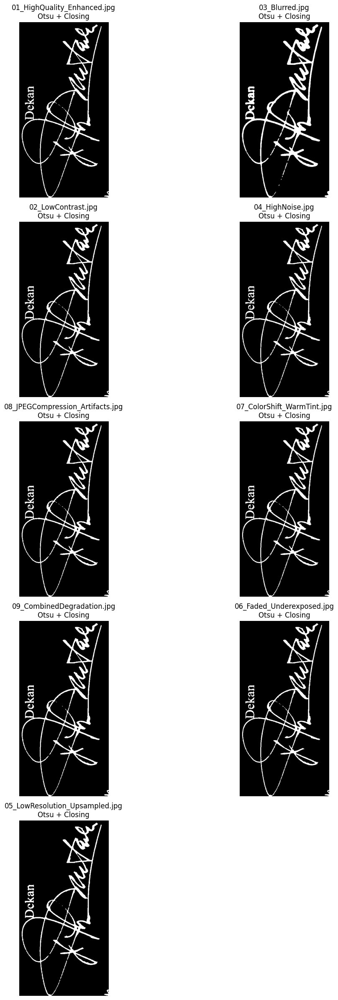

In [79]:
#Hasil closing
plt.figure(figsize=(12, 24))

for i, nama_file in enumerate(files):

    closing = closing_images[nama_file]

    plt.subplot(5, 2, i + 1)
    plt.imshow(closing, cmap="gray")
    plt.title(
        nama_file.replace("Copy of ", "") +
        "\nOtsu + Closing"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

##Perhitung karakteristik area hasil segmentasi closing

In [80]:
closing_results = []

for nama_file, closing in closing_images.items():

    foreground = np.sum(closing == 255)

    total_pixels = closing.shape[0] * closing.shape[1]

    percentage = (foreground / total_pixels) * 100

    closing_results.append({
        "file": nama_file,
        "foreground": foreground,
        "percentage": percentage
    })

for data in closing_results:

    print(
        data["file"],
        "| Foreground:", data["foreground"],
        "| Percentage:",
        f"{data['percentage']:.2f}%"
    )

Copy of 01_HighQuality_Enhanced.jpg | Foreground: 27371 | Percentage: 8.72%
Copy of 03_Blurred.jpg | Foreground: 37626 | Percentage: 11.98%
Copy of 02_LowContrast.jpg | Foreground: 27535 | Percentage: 8.77%
Copy of 04_HighNoise.jpg | Foreground: 27149 | Percentage: 8.65%
Copy of 08_JPEGCompression_Artifacts.jpg | Foreground: 27376 | Percentage: 8.72%
Copy of 07_ColorShift_WarmTint.jpg | Foreground: 27471 | Percentage: 8.75%
Copy of 09_CombinedDegradation.jpg | Foreground: 28599 | Percentage: 9.11%
Copy of 06_Faded_Underexposed.jpg | Foreground: 27442 | Percentage: 8.74%
Copy of 05_LowResolution_Upsampled.jpg | Foreground: 29519 | Percentage: 9.40%


## 9. Karakteristik Area Hasil Segmentasi

Karakteristik area hasil segmentasi dianalisis berdasarkan jumlah dan
persentase piksel foreground. Persentase foreground digunakan sebagai
fitur untuk melihat seberapa besar area yang tersegmentasi sebagai
foreground setelah proses thresholding dan morphological operation.

Tabel berikut menunjukkan perbandingan hasil segmentasi pada 9 citra
yang memiliki tanda tangan.

In [81]:
# Membuat tabel hasil perbandingan
comparison_results = []

for nama_file in files:

    # Global Threshold
    global_img = global_threshold_images[nama_file]
    global_foreground = np.sum(global_img == 255)
    global_percentage = (
        global_foreground / global_img.size
    ) * 100

    # Otsu
    otsu_img = otsu_threshold_images[nama_file]
    otsu_foreground = np.sum(otsu_img == 255)
    otsu_percentage = (
        otsu_foreground / otsu_img.size
    ) * 100

    # Opening
    opening_img = opening_images[nama_file]
    opening_foreground = np.sum(opening_img == 255)
    opening_percentage = (
        opening_foreground / opening_img.size
    ) * 100

    # Closing
    closing_img = closing_images[nama_file]
    closing_foreground = np.sum(closing_img == 255)
    closing_percentage = (
        closing_foreground / closing_img.size
    ) * 100

    # Nilai threshold Otsu
    otsu_value = otsu_values[nama_file]

    # Masukkan ke tabel
    comparison_results.append({
        "Citra": nama_file.replace("Copy of ", ""),
        "Global (%)": global_percentage,
        "Otsu Threshold": otsu_value,
        "Otsu (%)": otsu_percentage,
        "Opening (%)": opening_percentage,
        "Closing (%)": closing_percentage
    })

# Buat DataFrame
df_comparison = pd.DataFrame(comparison_results)

# Membulatkan angka persentase
df_comparison["Global (%)"] = df_comparison["Global (%)"].round(2)
df_comparison["Otsu (%)"] = df_comparison["Otsu (%)"].round(2)
df_comparison["Opening (%)"] = df_comparison["Opening (%)"].round(2)
df_comparison["Closing (%)"] = df_comparison["Closing (%)"].round(2)
df_comparison["Otsu Threshold"] = df_comparison["Otsu Threshold"].round(0)

# Tampilkan tabel
df_comparison

,Citra,Global (%),Otsu Threshold,Otsu (%),Opening (%),Closing (%)
0,01_HighQuality_Enhanced.jpg,7.55,157.0,8.45,7.86,8.72
1,03_Blurred.jpg,3.00,197.0,11.95,11.87,11.98
2,02_LowContrast.jpg,1.07,198.0,8.53,8.02,8.77
3,04_HighNoise.jpg,6.74,164.0,8.29,7.53,8.65
4,08_JPEGCompression_Artifacts.jpg,6.68,171.0,8.57,8.15,8.72
5,07_ColorShift_WarmTint.jpg,7.07,164.0,8.52,8.01,8.75
6,09_CombinedDegradation.jpg,7.59,143.0,9.05,8.81,9.11
7,06_Faded_Underexposed.jpg,8.80,123.0,8.54,8.06,8.74
8,05_LowResolution_Upsampled.jpg,5.69,180.0,9.34,9.17,9.40


## Visualisasi Otsu, Opening, dan Closing untuk semua gambar

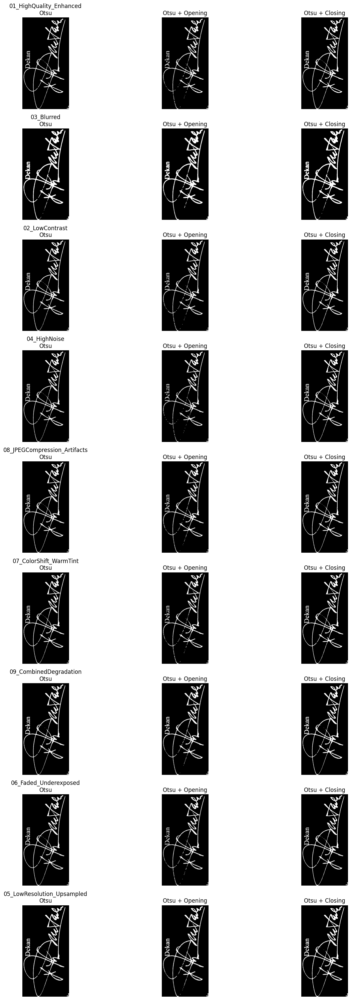

In [82]:
plt.figure(figsize=(15, 30))

for i, nama_file in enumerate(files):

    otsu = otsu_threshold_images[nama_file]
    opening = opening_images[nama_file]
    closing = closing_images[nama_file]

    nama_singkat = nama_file.replace("Copy of ", "").replace(".jpg", "")

    # Otsu
    plt.subplot(len(files), 3, i * 3 + 1)
    plt.imshow(otsu, cmap="gray")
    plt.title(f"{nama_singkat}\nOtsu")
    plt.axis("off")

    # Opening
    plt.subplot(len(files), 3, i * 3 + 2)
    plt.imshow(opening, cmap="gray")
    plt.title("Otsu + Opening")
    plt.axis("off")

    # Closing
    plt.subplot(len(files), 3, i * 3 + 3)
    plt.imshow(closing, cmap="gray")
    plt.title("Otsu + Closing")
    plt.axis("off")

plt.tight_layout()
plt.show()

##Grafik hasil perbandingan

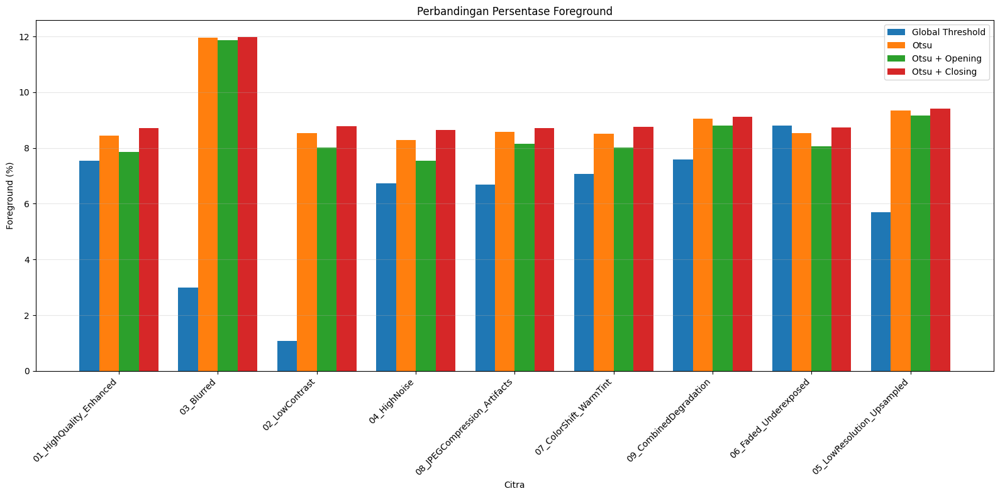

In [83]:
# Nama gambar
labels = [
    nama.replace("Copy of ", "").replace(".jpg", "")
    for nama in df_comparison["Citra"]
]

x = np.arange(len(labels))
width = 0.2

# Data persentase
global_values = df_comparison["Global (%)"].values
otsu_values_plot = df_comparison["Otsu (%)"].values
opening_values = df_comparison["Opening (%)"].values
closing_values = df_comparison["Closing (%)"].values

# Buat figure
plt.figure(figsize=(16, 8))

plt.bar(
    x - 1.5 * width,
    global_values,
    width,
    label="Global Threshold"
)

plt.bar(
    x - 0.5 * width,
    otsu_values_plot,
    width,
    label="Otsu"
)

plt.bar(
    x + 0.5 * width,
    opening_values,
    width,
    label="Otsu + Opening"
)

plt.bar(
    x + 1.5 * width,
    closing_values,
    width,
    label="Otsu + Closing"
)

plt.xlabel("Citra")
plt.ylabel("Foreground (%)")
plt.title("Perbandingan Persentase Foreground")
plt.xticks(x, labels, rotation=45, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 10 Absent Signature


## 10. Pengujian SIGNATURE ABSENT

Untuk menguji kemampuan sistem dalam membedakan citra yang memiliki
dan tidak memiliki tanda tangan, digunakan 9 citra `SIGNATURE ABSENT`.

Citra tersebut berasal dari citra yang sama dengan kelas
`SIGNATURE PRESENT`, tetapi tanda tangan pada area yang dianalisis
telah dihilangkan.

Pendekatan ini digunakan agar kondisi dokumen seperti ukuran, posisi,
dan karakteristik degradasi tetap relatif sebanding antara kedua
kelas.

In [84]:
absent_folder = "/content/drive/MyDrive/signature absent "

absent_files = os.listdir(absent_folder)

print(absent_files)

['gambar 9.jpg', 'gambar 6.jpg', 'gambar 2.jpg', 'gambar 1.jpg', 'gambar 4.jpg', 'gambar 3.jpg', 'gambar 7.jpg', 'gambar 8.jpg', 'gambar 5.jpg']


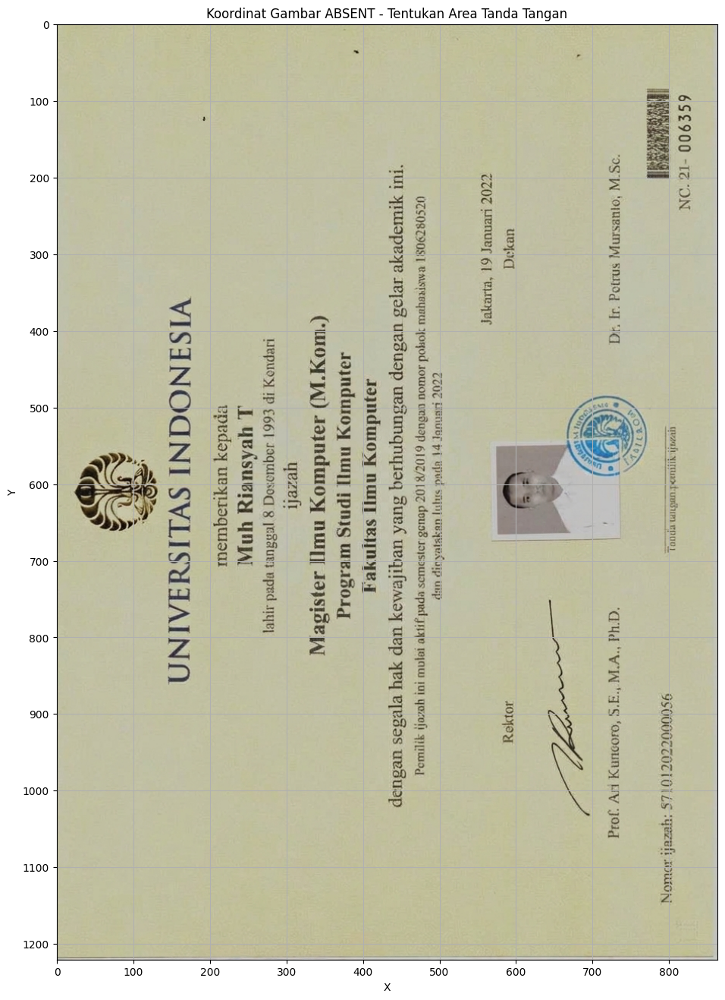

In [85]:
# Ambil satu gambar ABSENT
nama_file = absent_files[0]
path = os.path.join(absent_folder, nama_file)

img_absent = cv2.imread(path)
img_absent_rgb = cv2.cvtColor(img_absent, cv2.COLOR_BGR2RGB)

# Tampilkan dengan koordinat
plt.figure(figsize=(12, 16))
plt.imshow(img_absent_rgb)

plt.xticks(range(0, 865, 100))
plt.yticks(range(0, 1222, 100))
plt.grid()

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Koordinat Gambar ABSENT - Tentukan Area Tanda Tangan")

plt.show()

In [86]:
# Menyimpan hasil crop gambar ABSENT
absent_crops = {}

# Koordinat crop yang sama dengan gambar PRESENT
x1 = 573
y1 = 167
x2 = 713
y2 = 441
for nama_file in absent_files:

    path = os.path.join(absent_folder, nama_file)

    # Baca gambar
    img_absent = cv2.imread(path)

    # Crop area tanda tangan
    crop_absent = img_absent[y1:y2, x1:x2]

    # Simpan
    absent_crops[nama_file] = crop_absent

print("Berhasil melakukan crop pada",
      len(absent_crops), "gambar ABSENT.")

Berhasil melakukan crop pada 9 gambar ABSENT.


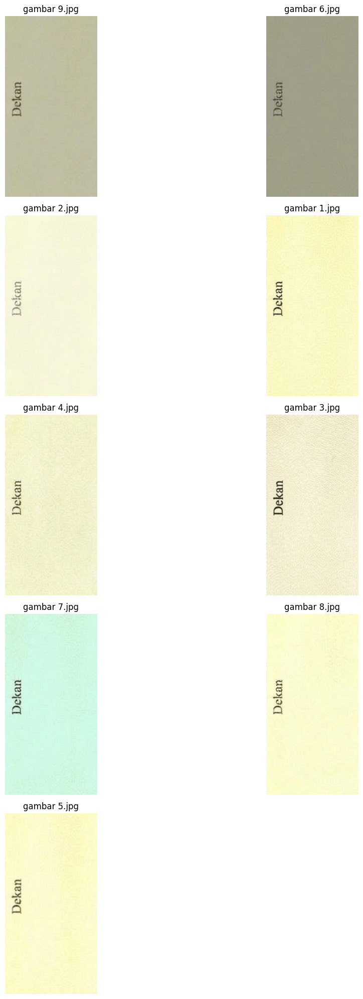

In [87]:
plt.figure(figsize=(12, 20))

for i, nama_file in enumerate(absent_files):

    crop = absent_crops[nama_file]

    crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

    plt.subplot(5, 2, i + 1)
    plt.imshow(crop_rgb)
    plt.title(nama_file)
    plt.axis("off")

plt.tight_layout()
plt.show()

Berhasil mengubah 9 gambar ABSENT menjadi grayscale.


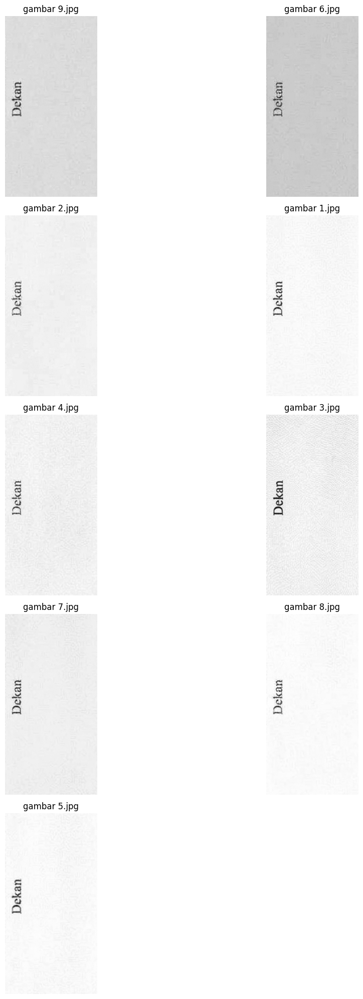

In [88]:
# Menyimpan hasil grayscale ABSENT
absent_grayscale_images = {}

for nama_file, crop in absent_crops.items():

    # Konversi BGR ke grayscale
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)

    # Simpan
    absent_grayscale_images[nama_file] = gray

print(
    "Berhasil mengubah",
    len(absent_grayscale_images),
    "gambar ABSENT menjadi grayscale."
)

plt.figure(figsize=(12, 20))

for i, nama_file in enumerate(absent_files):

    gray = absent_grayscale_images[nama_file]

    plt.subplot(5, 2, i + 1)
    plt.imshow(gray, cmap="gray")
    plt.title(nama_file)
    plt.axis("off")

plt.tight_layout()
plt.show()

Otsu Threshold berhasil diterapkan pada 9 gambar ABSENT.


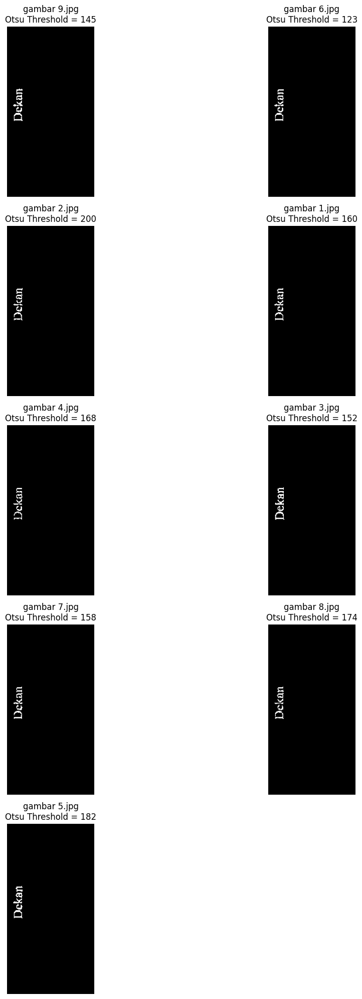

In [89]:
# Menyimpan hasil Otsu untuk gambar ABSENT
absent_otsu_images = {}

# Menyimpan nilai threshold Otsu
absent_otsu_values = {}

for nama_file, gray in absent_grayscale_images.items():

    # Otsu Threshold
    otsu_value, otsu_thresh = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Simpan hasil
    absent_otsu_images[nama_file] = otsu_thresh
    absent_otsu_values[nama_file] = otsu_value

print(
    "Otsu Threshold berhasil diterapkan pada",
    len(absent_otsu_images),
    "gambar ABSENT."
)

plt.figure(figsize=(12, 20))

for i, nama_file in enumerate(absent_files):

    otsu = absent_otsu_images[nama_file]
    otsu_value = absent_otsu_values[nama_file]

    plt.subplot(5, 2, i + 1)
    plt.imshow(otsu, cmap="gray")
    plt.title(
        f"{nama_file}\nOtsu Threshold = {otsu_value:.0f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

Morphological Opening berhasil diterapkan pada 9 gambar ABSENT.


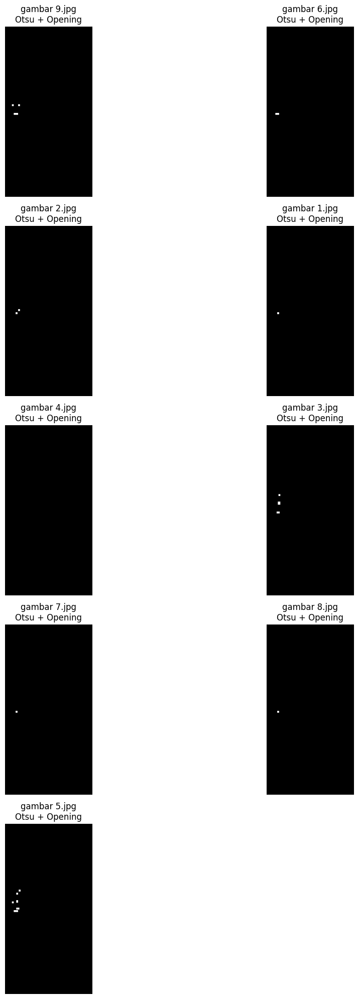

In [90]:
# Kernel morphology
kernel = np.ones((3, 3), np.uint8)

# Menyimpan hasil Opening ABSENT
absent_opening_images = {}

for nama_file, otsu in absent_otsu_images.items():

    # Morphological Opening
    opening = cv2.morphologyEx(
        otsu,
        cv2.MORPH_OPEN,
        kernel
    )

    # Simpan hasil
    absent_opening_images[nama_file] = opening

print(
    "Morphological Opening berhasil diterapkan pada",
    len(absent_opening_images),
    "gambar ABSENT."
)

plt.figure(figsize=(12, 20))

for i, nama_file in enumerate(absent_files):

    opening = absent_opening_images[nama_file]

    plt.subplot(5, 2, i + 1)
    plt.imshow(opening, cmap="gray")
    plt.title(f"{nama_file}\nOtsu + Opening")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [91]:
absent_opening_results = []

for nama_file, opening in absent_opening_images.items():

    foreground = np.sum(opening == 255)

    total_pixels = opening.shape[0] * opening.shape[1]

    percentage = (foreground / total_pixels) * 100

    absent_opening_results.append({
        "file": nama_file,
        "foreground": foreground,
        "percentage": percentage
    })

for data in absent_opening_results:
    print(
        data["file"],
        "| Foreground:", data["foreground"],
        "| Percentage:",
        f"{data['percentage']:.2f}%"
    )

gambar 9.jpg | Foreground: 39 | Percentage: 0.10%
gambar 6.jpg | Foreground: 18 | Percentage: 0.05%
gambar 2.jpg | Foreground: 18 | Percentage: 0.05%
gambar 1.jpg | Foreground: 9 | Percentage: 0.02%
gambar 4.jpg | Foreground: 0 | Percentage: 0.00%
gambar 3.jpg | Foreground: 44 | Percentage: 0.11%
gambar 7.jpg | Foreground: 9 | Percentage: 0.02%
gambar 8.jpg | Foreground: 9 | Percentage: 0.02%
gambar 5.jpg | Foreground: 75 | Percentage: 0.20%


Morphological Closing berhasil diterapkan pada 9 gambar ABSENT.


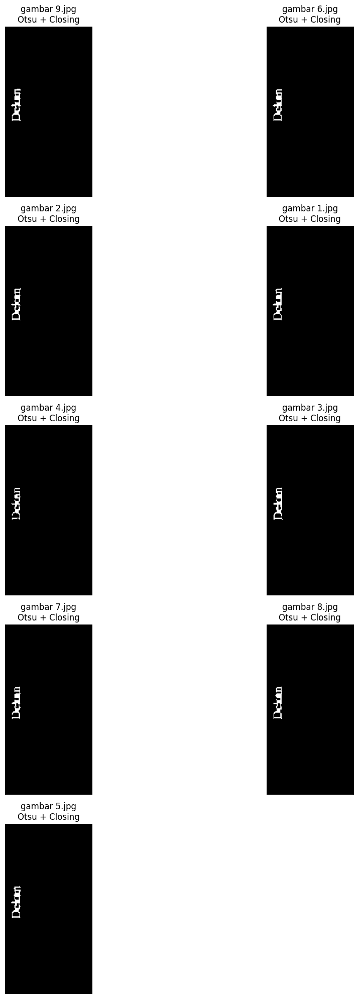

In [92]:
# Kernel morphology yang sama
kernel = np.ones((3, 3), np.uint8)

# Menyimpan hasil Closing ABSENT
absent_closing_images = {}

for nama_file, otsu in absent_otsu_images.items():

    # Morphological Closing
    closing = cv2.morphologyEx(
        otsu,
        cv2.MORPH_CLOSE,
        kernel
    )

    # Simpan hasil
    absent_closing_images[nama_file] = closing

print(
    "Morphological Closing berhasil diterapkan pada",
    len(absent_closing_images),
    "gambar ABSENT."
)

plt.figure(figsize=(12, 20))

for i, nama_file in enumerate(absent_files):

    closing = absent_closing_images[nama_file]

    plt.subplot(5, 2, i + 1)
    plt.imshow(closing, cmap="gray")
    plt.title(f"{nama_file}\nOtsu + Closing")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [93]:
# Hitung foreground hasil Closing untuk ABSENT

absent_closing_results = []

for nama_file, closing in absent_closing_images.items():

    foreground = np.sum(closing == 255)

    total_pixels = closing.shape[0] * closing.shape[1]

    percentage = (foreground / total_pixels) * 100

    absent_closing_results.append({
        "file": nama_file,
        "foreground": foreground,
        "percentage": percentage
    })

for data in absent_closing_results:
    print(
        data["file"],
        "| Foreground:", data["foreground"],
        "| Percentage:",
        f"{data['percentage']:.2f}%"
    )


gambar 9.jpg | Foreground: 341 | Percentage: 0.89%
gambar 6.jpg | Foreground: 321 | Percentage: 0.84%
gambar 2.jpg | Foreground: 319 | Percentage: 0.83%
gambar 1.jpg | Foreground: 314 | Percentage: 0.82%
gambar 4.jpg | Foreground: 278 | Percentage: 0.72%
gambar 3.jpg | Foreground: 357 | Percentage: 0.93%
gambar 7.jpg | Foreground: 314 | Percentage: 0.82%
gambar 8.jpg | Foreground: 314 | Percentage: 0.82%
gambar 5.jpg | Foreground: 340 | Percentage: 0.89%


## 11. Aturan Klasifikasi

Persentase foreground digunakan sebagai fitur untuk menentukan
keberadaan tanda tangan.

Nilai threshold klasifikasi ditentukan berdasarkan titik tengah antara
nilai foreground maksimum pada kelas `SIGNATURE ABSENT` dan nilai
foreground minimum pada kelas `SIGNATURE PRESENT`.

Aturan yang digunakan adalah:

- Jika `Foreground (%) >= threshold`, maka hasil klasifikasi adalah
  **SIGNATURE PRESENT**.
- Jika `Foreground (%) < threshold`, maka hasil klasifikasi adalah
  **SIGNATURE ABSENT**.

In [94]:
# ==========================================
# HASIL PRESENT - OTSU + OPENING
# ==========================================

present_results = []

for nama_file, opening in opening_images.items():

    foreground = np.sum(opening == 255)
    total_pixels = opening.size
    percentage = (foreground / total_pixels) * 100

    present_results.append({
        "File": nama_file,
        "Kelas Aktual": "SIGNATURE PRESENT",
        "Foreground": foreground,
        "Foreground (%)": percentage
    })


# ==========================================
# HASIL ABSENT - OTSU + OPENING
# ==========================================

absent_results = []

for nama_file, opening in absent_opening_images.items():

    foreground = np.sum(opening == 255)
    total_pixels = opening.size
    percentage = (foreground / total_pixels) * 100

    absent_results.append({
        "File": nama_file,
        "Kelas Aktual": "SIGNATURE ABSENT",
        "Foreground": foreground,
        "Foreground (%)": percentage
    })


# Gabungkan
df_classification = pd.DataFrame(
    present_results + absent_results
)

# Bulatkan persentase
df_classification["Foreground (%)"] = (
    df_classification["Foreground (%)"].round(2)
)

# Tampilkan
df_classification

,File,Kelas Aktual,Foreground,Foreground (%)
0,Copy of 01_HighQuality_Enhanced.jpg,SIGNATURE PRESENT,24672,7.86
1,Copy of 03_Blurred.jpg,SIGNATURE PRESENT,37276,11.87
2,Copy of 02_LowContrast.jpg,SIGNATURE PRESENT,25193,8.02
3,Copy of 04_HighNoise.jpg,SIGNATURE PRESENT,23634,7.53
4,Copy of 08_JPEGCompression_Artifacts.jpg,SIGNATURE PRESENT,25600,8.15
5,Copy of 07_ColorShift_WarmTint.jpg,SIGNATURE PRESENT,25140,8.01
6,Copy of 09_CombinedDegradation.jpg,SIGNATURE PRESENT,27670,8.81
7,Copy of 06_Faded_Underexposed.jpg,SIGNATURE PRESENT,25323,8.06
8,Copy of 05_LowResolution_Upsampled.jpg,SIGNATURE PRESENT,28800,9.17
9,gambar 9.jpg,SIGNATURE ABSENT,39,0.10


In [95]:
present_values = df_classification[
    df_classification["Kelas Aktual"] == "SIGNATURE PRESENT"
]["Foreground (%)"]

absent_values = df_classification[
    df_classification["Kelas Aktual"] == "SIGNATURE ABSENT"
]["Foreground (%)"]

print("=== SIGNATURE PRESENT ===")
print("Minimum :", present_values.min(), "%")
print("Maksimum:", present_values.max(), "%")
print("Rata-rata:", present_values.mean().round(2), "%")

print("\n=== SIGNATURE ABSENT ===")
print("Minimum :", absent_values.min(), "%")
print("Maksimum:", absent_values.max(), "%")
print("Rata-rata:", absent_values.mean().round(2), "%")

=== SIGNATURE PRESENT ===
Minimum : 7.53 %
Maksimum: 11.87 %
Rata-rata: 8.61 %

=== SIGNATURE ABSENT ===
Minimum : 0.0 %
Maksimum: 0.2 %
Rata-rata: 0.06 %


In [96]:
# Threshold klasifikasi yang sudah dihitung sebelumnya
threshold_klasifikasi = (
    absent_values.max() + present_values.min()
) / 2

# Aturan klasifikasi
df_classification["Prediksi"] = np.where(
    df_classification["Foreground (%)"] >= threshold_klasifikasi,
    "SIGNATURE PRESENT",
    "SIGNATURE ABSENT"
)

print("Threshold klasifikasi:",
      round(threshold_klasifikasi, 2), "%")

display(df_classification)

Threshold klasifikasi: 3.87 %


,File,Kelas Aktual,Foreground,Foreground (%),Prediksi
0,Copy of 01_HighQuality_Enhanced.jpg,SIGNATURE PRESENT,24672,7.86,SIGNATURE PRESENT
1,Copy of 03_Blurred.jpg,SIGNATURE PRESENT,37276,11.87,SIGNATURE PRESENT
2,Copy of 02_LowContrast.jpg,SIGNATURE PRESENT,25193,8.02,SIGNATURE PRESENT
3,Copy of 04_HighNoise.jpg,SIGNATURE PRESENT,23634,7.53,SIGNATURE PRESENT
4,Copy of 08_JPEGCompression_Artifacts.jpg,SIGNATURE PRESENT,25600,8.15,SIGNATURE PRESENT
5,Copy of 07_ColorShift_WarmTint.jpg,SIGNATURE PRESENT,25140,8.01,SIGNATURE PRESENT
6,Copy of 09_CombinedDegradation.jpg,SIGNATURE PRESENT,27670,8.81,SIGNATURE PRESENT
7,Copy of 06_Faded_Underexposed.jpg,SIGNATURE PRESENT,25323,8.06,SIGNATURE PRESENT
8,Copy of 05_LowResolution_Upsampled.jpg,SIGNATURE PRESENT,28800,9.17,SIGNATURE PRESENT
9,gambar 9.jpg,SIGNATURE ABSENT,39,0.10,SIGNATURE ABSENT


## 12. Pengujian Sistem

Sistem diuji menggunakan total 18 citra yang terdiri dari 9 citra
`SIGNATURE PRESENT` dan 9 citra `SIGNATURE ABSENT`.

Hasil prediksi dibandingkan dengan kelas aktual untuk menghitung
akurasi sistem.

In [97]:
# Cek hasil klasifikasi
df_classification["Benar"] = (
    df_classification["Kelas Aktual"] ==
    df_classification["Prediksi"]
)

print(
    "Jumlah benar:",
    df_classification["Benar"].sum(),
    "dari",
    len(df_classification)
)

accuracy = (
    df_classification["Benar"].sum()
    / len(df_classification)
) * 100

print(f"Accuracy: {accuracy:.2f}%")

Jumlah benar: 18 dari 18
Accuracy: 100.00%


### Hasil Pengujian

Berdasarkan hasil pengujian, seluruh 18 citra berhasil diklasifikasikan
dengan benar.

- SIGNATURE PRESENT: 9/9 benar
- SIGNATURE ABSENT: 9/9 benar
- Total: 18/18 benar
- Accuracy: **100%**

## 13. Confusion Matrix

Confusion matrix digunakan untuk melihat jumlah prediksi benar dan
salah pada masing-masing kelas.

Hasil pengujian menunjukkan:

- True Positive = 9
- True Negative = 9
- False Positive = 0
- False Negative = 0

Dengan demikian, tidak terdapat kesalahan klasifikasi pada 18 citra
pengujian.

Confusion Matrix:
[[9 0]
 [0 9]]


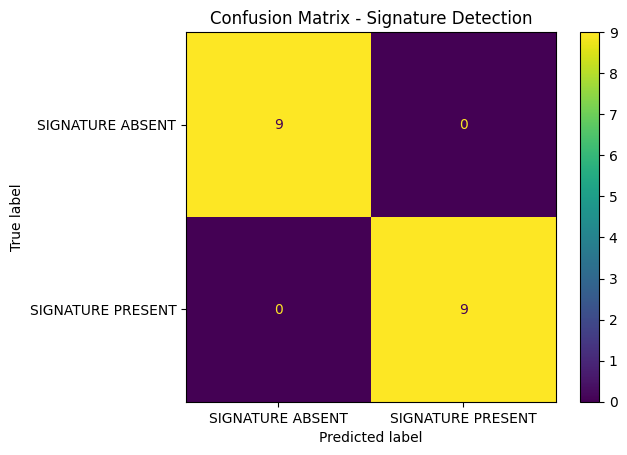

In [98]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = df_classification["Kelas Aktual"]
y_pred = df_classification["Prediksi"]

labels = [
    "SIGNATURE ABSENT",
    "SIGNATURE PRESENT"
]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot()
plt.title("Confusion Matrix - Signature Detection")
plt.show()

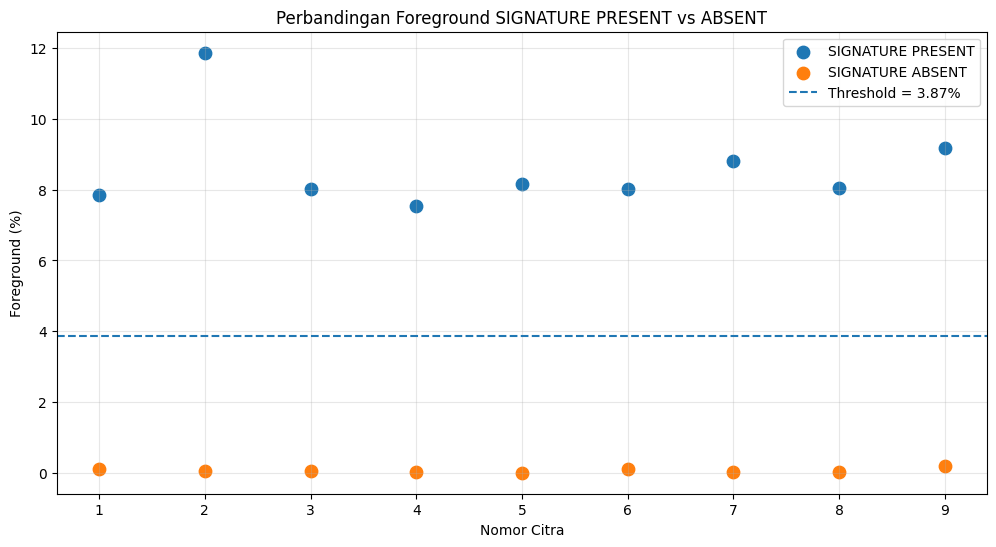

In [99]:
plt.figure(figsize=(12, 6))

present_values = df_classification[
    df_classification["Kelas Aktual"] == "SIGNATURE PRESENT"
]["Foreground (%)"]

absent_values = df_classification[
    df_classification["Kelas Aktual"] == "SIGNATURE ABSENT"
]["Foreground (%)"]

# Posisi data
present_x = range(1, len(present_values) + 1)
absent_x = range(1, len(absent_values) + 1)

plt.scatter(
    present_x,
    present_values,
    label="SIGNATURE PRESENT",
    s=80
)

plt.scatter(
    absent_x,
    absent_values,
    label="SIGNATURE ABSENT",
    s=80
)

# Garis threshold
plt.axhline(
    y=threshold_klasifikasi,
    linestyle="--",
    label=f"Threshold = {threshold_klasifikasi:.2f}%"
)

plt.xlabel("Nomor Citra")
plt.ylabel("Foreground (%)")
plt.title("Perbandingan Foreground SIGNATURE PRESENT vs ABSENT")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 14. Analisis

### 14.1 Mengapa Thresholding Diperlukan?

Thresholding diperlukan untuk memisahkan foreground dari background
pada citra. Dalam kasus ini, foreground digunakan untuk merepresentasikan
piksel yang kemungkinan merupakan bagian dari tanda tangan.

Setelah citra dikonversi menjadi citra biner, jumlah piksel foreground
dapat dihitung dan digunakan sebagai karakteristik untuk menganalisis
keberadaan tanda tangan.

Thresholding juga mempermudah penerapan morphological operation seperti
opening dan closing karena operasi tersebut bekerja berdasarkan struktur
foreground dan background pada citra biner.

Pada penelitian ini, Otsu digunakan karena nilai threshold dapat
ditentukan secara otomatis berdasarkan distribusi intensitas masing-
masing citra.

### 14.2 Pengaruh Threshold Terlalu Tinggi atau Terlalu Rendah

Jika threshold terlalu tinggi, sebagian piksel tanda tangan dapat
dianggap sebagai background. Akibatnya, area foreground menjadi terlalu
sedikit dan tanda tangan yang sebenarnya ada dapat gagal terdeteksi.
Kondisi ini dapat menyebabkan **False Negative**.

Sebaliknya, jika threshold terlalu rendah, piksel background dan noise
dapat ikut dianggap sebagai foreground. Akibatnya, area foreground
menjadi terlalu besar dan citra tanpa tanda tangan dapat dianggap
memiliki tanda tangan. Kondisi ini dapat menyebabkan **False Positive**.

Oleh karena itu, pemilihan threshold yang sesuai sangat penting agar
hasil segmentasi dapat merepresentasikan area tanda tangan dengan baik.